# Ridge, Lasso, Elastic Net and the outlier experiment

Regularization adds a penalty on the size of the coefficients. It trades a little bias for a large drop in variance, which is exactly what plain OLS on 280 features was missing in Phase 4.

Everything uses the linear preprocessor from Phase 2 (log on skewed areas, scaling, one-hot) and the shared folds.

In [1]:
# Make src/ importable from notebooks/ and reload edited modules automatically
%load_ext autoreload
%autoreload 2
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import (ElasticNetCV, HuberRegressor, Lasso, LassoCV,
                                  LinearRegression, Ridge, RidgeCV)
from sklearn.model_selection import KFold, cross_val_score, cross_validate, validation_curve
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer

from src.cv import (RAW_DIR, FIGURES_DIR, SEED, CV, SCORING, evaluate, fold_rmse,
                    log_result, oof_predict, show_results)
from src.features import make_linear_preprocessor, make_ols_subset

train = pd.read_csv(RAW_DIR / "train.csv")
X = train.drop(columns=["Id", "SalePrice"])
y = np.log1p(train["SalePrice"])

# Alpha grids. Ridge and Lasso use different scales in scikit-learn:
# Ridge penalizes the SUM of squared errors, Lasso the MEAN (1/2n), so Lasso's alphas are much smaller.
ridge_alphas = np.logspace(-2, 4, 40)
lasso_alphas = np.logspace(-4, 0, 30)

# The smallest Lasso alphas are close to plain OLS and can be slow to converge; that end overfits anyway
warnings.filterwarnings("ignore", category=ConvergenceWarning)

best Ridge alpha 8.377 -> CV RMSE 0.1316
best Lasso alpha 0.0009237 -> CV RMSE 0.1315


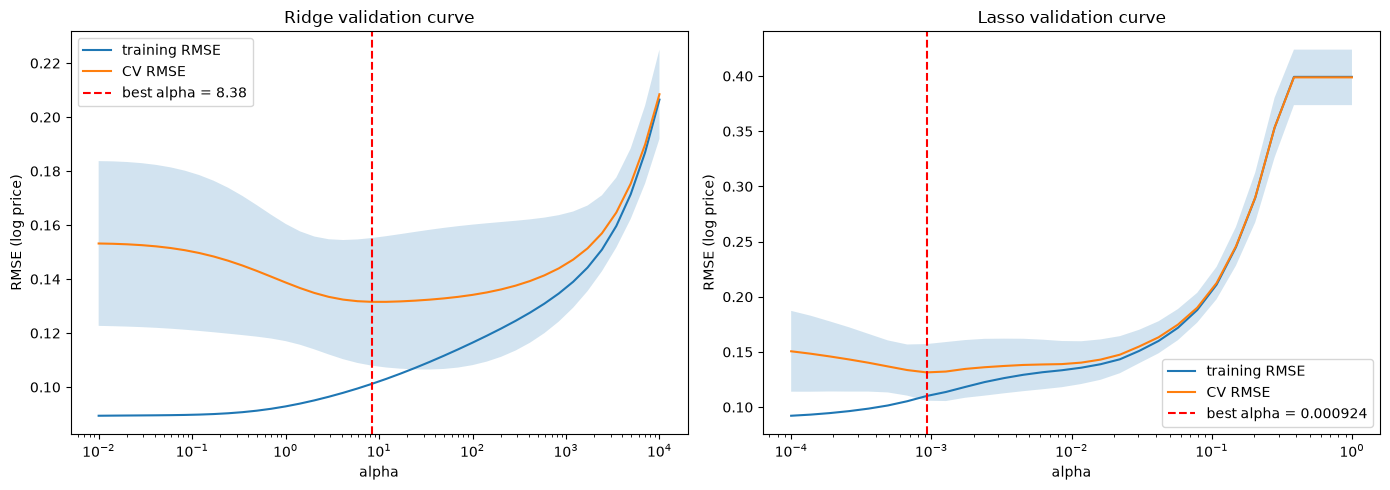

In [2]:
# Validation curves: CV RMSE (and training RMSE) for every alpha, on the shared folds
def val_curve(model, param_name, alphas):
    train_s, cv_s = validation_curve(model, X, y, param_name=param_name, param_range=alphas,
                                     cv=CV, scoring=SCORING, n_jobs=-1)
    return -train_s, -cv_s   # back to positive RMSE

ridge_pipe = Pipeline([("prep", make_linear_preprocessor()), ("model", Ridge())])
lasso_pipe = Pipeline([("prep", make_linear_preprocessor()), ("model", Lasso(max_iter=20000))])
ridge_train, ridge_cv = val_curve(ridge_pipe, "model__alpha", ridge_alphas)
lasso_train, lasso_cv = val_curve(lasso_pipe, "model__alpha", lasso_alphas)

best_ridge = ridge_alphas[ridge_cv.mean(axis=1).argmin()]
best_lasso = lasso_alphas[lasso_cv.mean(axis=1).argmin()]
print(f"best Ridge alpha {best_ridge:.4g} -> CV RMSE {ridge_cv.mean(axis=1).min():.4f}")
print(f"best Lasso alpha {best_lasso:.4g} -> CV RMSE {lasso_cv.mean(axis=1).min():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, alphas, tr, cv, best, name in [(axes[0], ridge_alphas, ridge_train, ridge_cv, best_ridge, "Ridge"),
                                       (axes[1], lasso_alphas, lasso_train, lasso_cv, best_lasso, "Lasso")]:
    ax.plot(alphas, tr.mean(axis=1), label="training RMSE")
    ax.plot(alphas, cv.mean(axis=1), label="CV RMSE")
    ax.fill_between(alphas, cv.mean(axis=1) - cv.std(axis=1), cv.mean(axis=1) + cv.std(axis=1), alpha=0.2)
    ax.axvline(best, color="red", ls="--", label=f"best alpha = {best:.3g}")
    ax.set(xscale="log", xlabel="alpha", ylabel="RMSE (log price)", title=f"{name} validation curve")
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_validation_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
# Ridge and Lasso at the best alpha, logged.
# Caution: alpha was picked by looking at these same folds, so this score is slightly optimistic.
ridge_best = make_pipeline(make_linear_preprocessor(), Ridge(alpha=best_ridge))
lasso_best = make_pipeline(make_linear_preprocessor(), Lasso(alpha=best_lasso, max_iter=20000))

s_ridge = evaluate(ridge_best, X, y, f"Ridge (alpha={best_ridge:.3g})", "linear_full", phase=5,
                   params={"alpha": best_ridge}, n_features=280, notes="alpha tuned on the same folds")

# Number of features Lasso actually keeps, from a fit on all training data
n_kept = int((lasso_best.fit(X, y)[-1].coef_ != 0).sum())
s_lasso = evaluate(lasso_best, X, y, f"Lasso (alpha={best_lasso:.3g})", "linear_full", phase=5,
                   params={"alpha": best_lasso}, n_features=n_kept, notes="alpha tuned on the same folds")

Ridge (alpha=8.38) [linear_full]: RMSE 0.1316 ± 0.0236 | folds [0.1274, 0.1235, 0.1775, 0.1193, 0.1103]
Lasso (alpha=0.000924) [linear_full]: RMSE 0.1315 ± 0.0257 | folds [0.1311, 0.1205, 0.1809, 0.1148, 0.1101]


In [ ]:
# Honest version: the *CV models pick alpha INSIDE each training fold (nested CV).
# The outer fold never influences the choice, so these scores have no tuning optimism.
inner_cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
nested = {
    "RidgeCV (nested)": RidgeCV(alphas=ridge_alphas),
    "LassoCV (nested)": LassoCV(alphas=lasso_alphas, cv=inner_cv, max_iter=20000),
    "ElasticNetCV (nested)": ElasticNetCV(alphas=lasso_alphas, l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 1.0],
                                          cv=inner_cv, max_iter=20000),
}
nested_scores = {}
for name, reg in nested.items():
    res = cross_validate(make_pipeline(make_linear_preprocessor(), reg), X, y, cv=CV,
                         scoring=SCORING, return_estimator=True, n_jobs=-1)
    scores = -res["test_score"]
    nested_scores[name] = scores
    chosen = [est[-1].alpha_ for est in res["estimator"]]
    extra = ""
    if name.startswith("ElasticNet"):
        extra = " | l1_ratio per fold " + str([est[-1].l1_ratio_ for est in res["estimator"]])
    print(f"{name}: RMSE {scores.mean():.4f} ± {scores.std():.4f} | alpha per fold {np.round(chosen, 5).tolist()}{extra}")
    log_result(name, "linear_full", {"alpha_per_fold": chosen}, scores, phase=5, n_features=280,
               notes="alpha chosen inside each training fold")

RidgeCV (nested): RMSE 0.1371 ± 0.0206 | alpha per fold [17.01254, 8.37678, 5.87802, 11.93777, 1.4251]


In [ ]:
# Coefficient paths: how each coefficient changes as alpha grows.
# Fitted once on all training data, only to look at coefficients (no scoring here).
prep = make_linear_preprocessor()
Xt = prep.fit_transform(X)
names = np.array([n.split("__", 1)[1] for n in prep.named_steps["columns"].get_feature_names_out()])

ridge_coefs = np.array([Ridge(alpha=a).fit(Xt, y).coef_ for a in ridge_alphas])

lasso_coefs = []
path_model = Lasso(warm_start=True, max_iter=20000)
for a in lasso_alphas[::-1]:                   # from strong to weak penalty, reusing the last solution
    path_model.set_params(alpha=a).fit(Xt, y)
    lasso_coefs.append(path_model.coef_.copy())
lasso_coefs = np.array(lasso_coefs)[::-1]      # back to increasing alpha

# The 15 largest coefficients of the best Ridge model
ridge_at_best = Ridge(alpha=best_ridge).fit(Xt, y).coef_
top15 = np.argsort(-np.abs(ridge_at_best))[:15]

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, alphas, coefs, best, name in [(axes[0], ridge_alphas, ridge_coefs, best_ridge, "Ridge"),
                                      (axes[1], lasso_alphas, lasso_coefs, best_lasso, "Lasso")]:
    for j in top15:
        ax.plot(alphas, coefs[:, j], label=names[j])
    ax.axvline(best, color="red", ls="--")
    ax.axhline(0, color="black", lw=0.5)
    ax.set(xscale="log", xlabel="alpha", title=f"{name} coefficient paths (top 15)")
axes[0].set_ylabel("coefficient")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_coef_paths.png", dpi=150, bbox_inches="tight")
plt.show()

# How many coefficients are exactly zero along the Lasso path
for a, c in list(zip(lasso_alphas, lasso_coefs))[::6]:
    print(f"alpha {a:.4g}: {(c != 0).sum()} of {len(c)} features kept")

In [ ]:
# What Lasso keeps and drops at the best alpha
lasso_coef = Lasso(alpha=best_lasso, max_iter=20000).fit(Xt, y).coef_
kept, dropped = names[lasso_coef != 0], names[lasso_coef == 0]
print(f"kept {len(kept)} of {len(names)} features")

num_names = set(n.split("__", 1)[1] for n in prep.named_steps["columns"].get_feature_names_out() if n.startswith("num__"))
print("\nnumeric features dropped:", sorted(set(dropped) & num_names))
print("one-hot columns dropped:", len(set(dropped) - num_names), "of", len(set(names) - num_names))

# The redundant pairs from the EDA: OLS vs Ridge vs Lasso coefficients (standardized features)
ols_coef = LinearRegression().fit(Xt, y).coef_
coef_table = pd.DataFrame({"OLS": ols_coef, "Ridge": ridge_at_best, "Lasso": lasso_coef}, index=names)
pairs = [("GarageCars", "GarageArea"), ("GrLivArea", "TotRmsAbvGrd"), ("TotalBsmtSF", "1stFlrSF"),
         ("YearBuilt", "GarageYrBlt"), ("YearBuilt", "HouseAge"), ("GrLivArea", "TotalSF")]
for a, b in pairs:
    print(f"\n{a} vs {b}")
    print(coef_table.loc[[a, b]].round(4).to_string())

In [ ]:
# Outlier experiment, done fairly:
# the folds stay the same, the outliers are only removed from the TRAINING folds,
# and every variant is scored on the same houses.
is_bad2 = train["Id"].isin([524, 1299]).to_numpy()
is_big4 = (train["GrLivArea"] > 4000).to_numpy()
print("houses above 4,000 sq ft:", int(is_big4.sum()), "->", train.loc[is_big4, "Id"].tolist())

ols_cv = Pipeline([("subset", FunctionTransformer(make_ols_subset)),
                   ("impute", SimpleImputer(strategy="median")),
                   ("ols", LinearRegression())])
models = {"OLS (17 features)": ols_cv, f"Ridge (alpha={best_ridge:.3g})": ridge_best}
variants = {"keep all": np.ones(len(y), dtype=bool),
            "drop 524 & 1299": ~is_bad2,
            "drop all > 4000 sq ft": ~is_big4}

rows, oof = [], {}
for mname, model in models.items():
    for vname, keep in variants.items():
        pred = oof_predict(model, X, y, train_keep=keep)
        oof[(mname, vname)] = pred
        s_all = fold_rmse(y, pred)
        s_normal = fold_rmse(y, pred, score_keep=~is_big4)
        rows.append({"model": mname, "training data": vname,
                     "RMSE all houses": s_all.mean(), "RMSE without the 4 big houses": s_normal.mean(),
                     "fold 3 (all houses)": s_all[2]})
outlier_table = pd.DataFrame(rows)
print(outlier_table.round(4).to_string(index=False))

In [ ]:
# The tempting but misleading way: delete the 2 houses from the data, then run CV.
# The folds are different (1,458 rows) and the 2 hardest houses are no longer scored at all.
X2, y2 = X.loc[~is_bad2], y.loc[~is_bad2]
naive = -cross_val_score(ridge_best, X2, y2, cv=CV, scoring=SCORING, n_jobs=-1)
print(f"Ridge, outliers deleted before CV: {naive.mean():.4f} ± {naive.std():.4f}   (NOT comparable)")

# What happens to the outliers' own predictions
for mname in models:
    for vname in ["keep all", "drop 524 & 1299"]:
        p = oof[(mname, vname)][is_bad2]
        print(f"{mname:22s} {vname:16s} predicted $ {np.expm1(p).round(-3).tolist()} "
              f"vs actual {train.loc[is_bad2, 'SalePrice'].tolist()}")

# Log the fair 'drop 524 & 1299' runs (scored on all houses, same folds as everything else)
n_feats = {"OLS (17 features)": 17, f"Ridge (alpha={best_ridge:.3g})": 280}
for mname in models:
    pred = oof[(mname, "drop 524 & 1299")]
    log_result(mname, "train without 524 & 1299", {}, fold_rmse(y, pred), phase=5, n_features=n_feats[mname],
               notes=f"scored on all houses; without the 4 big: {fold_rmse(y, pred, ~is_big4).mean():.4f}")

In [ ]:
# Robust alternative: Huber regression keeps the outliers but limits their pull.
# Squared loss for small residuals, linear loss beyond epsilon (in units of the residual scale).
huber_rows = []
for a in [1, 3, 10, 30, 100]:
    hub = make_pipeline(make_linear_preprocessor(), HuberRegressor(epsilon=1.35, alpha=a, max_iter=5000))
    pred = oof_predict(hub, X, y)
    huber_rows.append({"alpha": a, "RMSE all houses": fold_rmse(y, pred).mean(),
                       "RMSE without the 4 big houses": fold_rmse(y, pred, ~is_big4).mean(), "pred": pred})
huber_table = pd.DataFrame(huber_rows)
print(huber_table.drop(columns="pred").round(4).to_string(index=False))

best_h = huber_table.loc[huber_table["RMSE all houses"].idxmin()]
s_huber = fold_rmse(y, best_h["pred"])
log_result(f"Huber (alpha={best_h['alpha']:g})", "linear_full", {"alpha": best_h["alpha"], "epsilon": 1.35},
           s_huber, phase=5, n_features=280, notes="outliers kept; alpha tuned on the same folds")
print(f"\nHuber logged: {s_huber.mean():.4f} ± {s_huber.std():.4f} | folds {s_huber.round(4).tolist()}")

In [ ]:
# Fold by fold against Ridge: which differences are bigger than the noise?
s_ridge_drop = fold_rmse(y, oof[(f"Ridge (alpha={best_ridge:.3g})", "drop 524 & 1299")])
compare = {"Lasso": s_lasso, "ElasticNetCV (nested)": nested_scores["ElasticNetCV (nested)"],
           "Huber": s_huber, "Ridge, train without 524 & 1299": s_ridge_drop}
print("Ridge folds:", s_ridge.round(4).tolist())
for name, s in compare.items():
    d = s_ridge - s   # positive = the other model is better on that fold
    print(f"{name:32s} mean diff {d.mean():+.4f} | better on {int((d > 0).sum())} of 5 folds | folds {d.round(4).tolist()}")

In [ ]:
# The results table so far
print(show_results().to_string())